# Final plots — Samoa showcase

The figures meant to actually represent this case in the **GUI results
portal** ("Final Plots" tab) — the same 4-figure shape as
`NewSouthWales/12_Final_Plots.ipynb` (this notebook used to be
`00_Course_Figures.ipynb`, teaching-oriented slides; renamed and trimmed to
match, since it was already what populated `outputs/gui_figures/` that the
GUI reads). Last step in the pipeline, after validation (09-11).

**Story arc**
1. Domain — satellite + bathymetry + isobaths, AoI, the full mesh, and
   goals/sectors (no buoy — it only added noise here)
2. Reconstruction comparison — dynamic SnapWave vs. the metamodel, for a
   stormy moment and a calm moment, at every isobath + buoy site
3. Metamodel training — sampled SnapWave LHS cases per goal (notebook 05)
4. Reconstruction spectra network — spectra bubbles along the 5 m isobath +
   forcing arrows, for one moment

**Outputs:** `outputs/gui_figures/*.png` — kept at this path since that's what
the case contract and the GUI actually read (`GUI/README.md`); only the
notebook that produces them moved/renamed.

**Prerequisites:** goals GPKG, WHACS zarr, SnapWave LHS cases, fitted
models, the mesh netCDF (`inputs/GRID/`), a consolidated dynamic-hindcast
file (`Dynamic_Cases_WHACS_<comparison_period>.nc` — 2020 exists for this
case), and reconstruction spectra caches for `period` (notebooks 05-08, 11).


In [ ]:
from pathlib import Path

import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from bluemath_tk.core.plotting.spectra import render_spectrum_bubble
from utils.config import (
    PATHS,
    SIMULATIONS,
    goals_for_snapwave,
    load_goals,
    open_offshore_waves,
    resolve,
)
from utils import validation as val
from utils import metamodel as mm
from utils import onshore_sites as obs
from utils.simulation import SnapWaveCaseSetup
from utils import viz as cp

## Configuration & helpers


In [ ]:
# --- slide / export settings ---
EXPORT_DIR = resolve("outputs/gui_figures")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
DPI = 200
FIGSIZE_WIDE = (13.33, 7.5)  # 16:9
FIGSIZE_TALL = (10.0, 11.0)

# --- case study ---
period = "2020-01"
forcing_moment = None  # None -> storm peak at buoy goal
offshore_name = "WHACS"
mda_n = 450
pca_variance = 0.99
wl = 0.0

buoy_instrument = "Aunuu_Buoy"
buoy_site = obs.snapwave_site_id(buoy_instrument)

# The dynamic-vs-metamodel comparison figure needs a consolidated dynamic
# hindcast file (Dynamic_Cases_WHACS_<year>.nc) — 2020 is the one that
# exists for this case, matching `period` above already being within 2020.
# Kept as its own variable rather than reusing `period` so this doesn't
# silently break if `period` ever narrows to something outside that year.
comparison_period = "2020"
dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"])
    / f"Dynamic_Cases_{offshore_name}_{comparison_period}.nc"
)

GOALS_GPKG = resolve(SIMULATIONS["goals_file"]).with_suffix(".gpkg")
goals = load_goals()
goals_config = goals_for_snapwave(goals)
targets = gpd.read_file(GOALS_GPKG, layer="targets")
boundary_snaps_gdf = gpd.read_file(GOALS_GPKG, layer="boundary_snaps")
boundary_snaps = {
    str(int(row.goal_id)): {
        "longitude": float(row.geometry.x),
        "latitude": float(row.geometry.y),
    }
    for _, row in boundary_snaps_gdf.iterrows()
}

snapwave_setup = SnapWaveCaseSetup.from_case(goals)
aoi_gdf = snapwave_setup.aoi_gdf
enclosure_polygon = snapwave_setup.enclosure_polygon
output_sites_df = snapwave_setup.output_sites_df

goal_map = val.closest_goals_table(
    [buoy_site], offshore_names=[offshore_name], goals=goals
)
buoy_goal = int(goal_map.goal.iloc[0])
print(f"Export dir       : {EXPORT_DIR}")
print(f"Period           : {period}")
print(f"Comparison period: {comparison_period}  (dynamic ref: {dynamic_path.name})")
print(f"Buoy site        : {buoy_site}  ->  closest goal G{buoy_goal}")


def apply_slide_style() -> None:
    plt.rcParams.update(
        {
            "font.size": 13,
            "axes.titlesize": 15,
            "axes.labelsize": 13,
            "legend.fontsize": 11,
            "figure.facecolor": "white",
            "savefig.facecolor": "white",
        }
    )


def save_fig(fig, name: str) -> Path:
    path = EXPORT_DIR / f"{name}.png"
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor="white")
    display(fig)  # renders inline here, and in the Jupyter Book build
    plt.close(fig)
    print(f"saved -> {path}")
    return path


def build_lhs_cases_df() -> pd.DataFrame:
    """Forcing table from SnapWave LHS NetCDFs (one file per goal)."""
    chunks: list[pd.DataFrame] = []
    for gid in sorted(goals, key=int):
        with xr.open_dataset(mm.cases_path(gid)) as ds:
            df = (
                ds[["tp_forcing", "dir_forcing", "spr_forcing", "wl_forcing"]]
                .to_dataframe()
                .reset_index()
            )
        df["goal"] = int(gid)
        df["tp"] = df["tp_forcing"]
        df["dir"] = df["dir_forcing"]
        df["spr"] = df["spr_forcing"]
        df["wl"] = df["wl_forcing"]
        chunks.append(df[["goal", "tp", "dir", "spr", "wl"]])
    return pd.concat(chunks, ignore_index=True)


def pick_storm_peak_time(goal_id: int, *, period_: str | None = None) -> pd.Timestamp:
    off = open_offshore_waves(offshore_name).sel(time=period_ or period, goal=goal_id)
    return pd.Timestamp(off["hs"].idxmax("time").values)


def pick_calm_time(goal_id: int, *, period_: str | None = None) -> pd.Timestamp:
    """Lowest-Hs moment in the offshore series — the "calm day" counterpart to
    :func:`pick_storm_peak_time`, for the reconstruction comparison figure."""
    off = open_offshore_waves(offshore_name).sel(time=period_ or period, goal=goal_id)
    return pd.Timestamp(off["hs"].idxmin("time").values)


apply_slide_style()

PARTITION_STYLE = {
    0: ("Wind sea (p0)", "#e41a1c"),
    1: ("Swell 1 (p1)", "#377eb8"),
    2: ("Swell 2 (p2)", "#4daf4a"),
    3: ("Swell 3 (p3)", "#984ea3"),
}


def resolve_forcing_moment(goal_id: int | None = None) -> pd.Timestamp:
    if forcing_moment is not None:
        return pd.Timestamp(forcing_moment)
    gid = buoy_goal if goal_id is None else goal_id
    return pick_storm_peak_time(gid)


def offshore_partitions_at(time: pd.Timestamp) -> xr.Dataset:
    return open_offshore_waves(offshore_name).sel(time=time, method="nearest")


def _partition_arrowprops(
    lon: float,
    lat: float,
    dir_deg: float,
    *,
    scale_deg: float,
    color: str,
    lw: float = 2.4,
    alpha: float = 0.92,
):
    """Arrow style with larger heads for course maps."""
    theta = np.deg2rad(float(dir_deg))
    dlon = np.sin(theta) * scale_deg
    dlat = np.cos(theta) * scale_deg
    return (
        dict(
            arrowstyle="-|>",
            color=color,
            lw=lw,
            alpha=alpha,
            shrinkA=0,
            shrinkB=2,
            mutation_scale=16,
        ),
        (lon + dlon, lat + dlat),
        (lon, lat),
    )


def course_map_extent(
    *, pad_lon: float = 0.15, pad_lat: float = 0.12
) -> tuple[float, float, float, float]:
    """Lon/lat limits that include AoI, all goals, WHACS nodes, and buoy."""
    lons: list[float] = []
    lats: list[float] = []
    for g in goals.values():
        lons.append(g["target"]["longitude"])
        lats.append(g["target"]["latitude"])
        hc = g["hindcast"]["whacs"]
        lons.append(hc["longitude"])
        lats.append(hc["latitude"])
    for snap in boundary_snaps.values():
        lons.append(snap["longitude"])
        lats.append(snap["latitude"])
    buoy = obs.get_coordinates()[buoy_instrument]
    lons.append(buoy["lon"])
    lats.append(buoy["lat"])
    bb = aoi_gdf.total_bounds
    lons.extend([float(bb[0]), float(bb[2])])
    lats.extend([float(bb[1]), float(bb[3])])
    return (
        min(lons) - pad_lon,
        max(lons) + pad_lon,
        min(lats) - pad_lat,
        max(lats) + pad_lat,
    )


def partition_legend_handles() -> list:
    """Legend entries with arrow glyphs for partition colours."""
    handles = []
    for part, (label, color) in sorted(PARTITION_STYLE.items()):
        handles.append(
            plt.Line2D(
                [0],
                [0],
                color=color,
                linewidth=3.2,
                marker=">",
                markersize=11,
                markeredgewidth=0,
                label=f"{label}  (dir = wave-from, len ∝ Hs)",
            )
        )
    handles.append(
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor="black",
            markersize=7,
            linestyle="None",
            label="goal boundary snap",
        )
    )
    return handles


def draw_goal_partition_arrows(
    ax,
    time: pd.Timestamp,
    *,
    arrow_base_deg: float = 0.30,
    hs_floor: float = 0.04,
    fan_offset_deg: float = 0.028,
) -> None:
    """Four partition arrows per goal (wave-from direction, length ∝ phs)."""
    off = offshore_partitions_at(time)
    goal_ids = sorted(int(g) for g in off.goal.values)
    part_vars = [f"phs{i}" for i in range(4)]
    hs_max = float(np.nanmax(off[part_vars].to_array("part").values))
    hs_max = max(hs_max, hs_floor)

    for gid in goal_ids:
        key = str(gid)
        snap = boundary_snaps[key]
        lon, lat = snap["longitude"], snap["latitude"]
        ax.plot(
            lon,
            lat,
            "o",
            color="white",
            markersize=7,
            markeredgecolor="black",
            markeredgewidth=1.0,
            zorder=6,
        )
        ax.annotate(
            f"G{gid}",
            (lon, lat),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color="#111111",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75),
            zorder=7,
        )

        for part in range(4):
            phs = float(off[f"phs{part}"].sel(goal=gid).values)
            pdir = float(off[f"pdir{part}"].sel(goal=gid).values)
            if not np.isfinite(phs) or phs < hs_floor or not np.isfinite(pdir):
                continue
            color = PARTITION_STYLE[part][1]
            scale = arrow_base_deg * (0.45 + 0.55 * phs / hs_max)
            theta = np.deg2rad(pdir)
            perp = theta + np.pi / 2
            shift = (part - 1.5) * fan_offset_deg
            lon0 = lon + shift * np.sin(perp)
            lat0 = lat + shift * np.cos(perp)
            props, xytext, xy = _partition_arrowprops(
                lon0,
                lat0,
                pdir,
                scale_deg=scale,
                color=color,
            )
            ax.annotate("", xy=xy, xytext=xytext, arrowprops=props, zorder=5)

Export dir       : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures
Period           : 2020-01
Comparison period: 2020  (dynamic ref: Dynamic_Cases_WHACS_2020.nc)
Buoy site        : buoy_Aunuu_Buoy  ->  closest goal G8


## Fig 1 — Domain

Satellite imagery with bathymetry (ocean only) and isobath contours
underneath, the AoI boundary, the full computational **mesh**, and goals
with their propagation **sectors** and WHACS hindcast links. No buoy here —
it only added visual noise to what's meant to be a clean domain overview.


Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


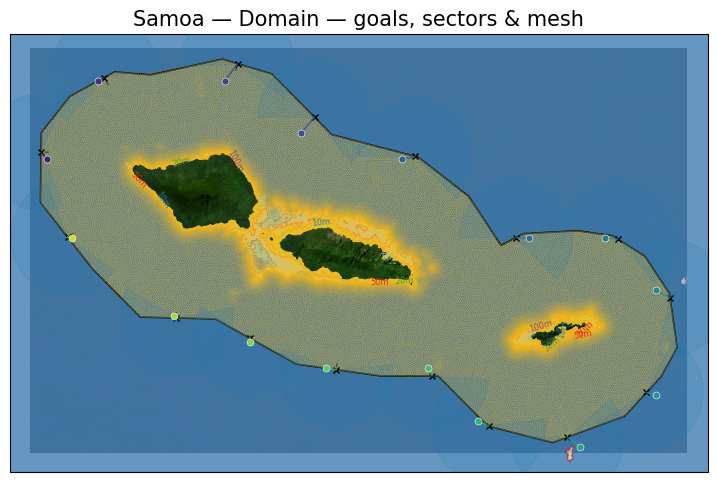

saved -> /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig01_domain.png


PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig01_domain.png')

In [ ]:
apply_slide_style()
goal_ids = sorted(int(k) for k in goals)
colors = cp._goal_colors(goal_ids)

fig, ax = cp.plot_base_map(
    title="Domain — goals, sectors & mesh",
    show_satellite=True,
    show_topobathy=True,
    show_isobaths=True,
    show_aoi=True,
)
cp.plot_mesh(PATHS["mesh_file"], ax)
cp.plot_sectors(targets, goals, boundary_snaps, ax, radius_deg=0.28)

for gid in goal_ids:
    key = str(gid)
    snap = boundary_snaps[key]
    hc = goals[key]["hindcast"]["whacs"]
    color = colors[gid]
    ax.plot(
        [snap["longitude"], hc["longitude"]],
        [snap["latitude"], hc["latitude"]],
        color=color,
        linewidth=1.2,
        alpha=0.75,
        zorder=5,
    )
    ax.plot(
        hc["longitude"],
        hc["latitude"],
        marker="o",
        color=color,
        markersize=5,
        markeredgecolor="white",
        markeredgewidth=0.4,
        zorder=6,
    )

x0, x1, y0, y1 = course_map_extent()
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)

save_fig(fig, "fig01_domain")

## Fig 2 — Reconstruction comparison: dynamic vs. metamodel

Hs at every isobath + buoy (+ mesh output) site (`site_source`), comparing
the full **dynamic** SnapWave hindcast against the **metamodel**
reconstruction, for a stormy moment and a calm moment (each found within
`comparison_period`, but only that single *day* is actually reconstructed
for each — same "restrict the time window" reasoning as Fig 4's spectra
network below: cost is dominated by per-goal model loading, not by how many
timesteps get reconstructed). Top row: storm peak. Bottom row: lowest-Hs
moment. Columns: dynamic, metamodel, difference (metamodel - dynamic).

Uses the same reconstruction path validated in
`09_Validate_Linear_Summation.ipynb` (`mm.reconstruct` for the metamodel
side, the consolidated `Dynamic_Cases_WHACS_<comparison_period>.nc` for the
dynamic reference, `val.align_pair` for the shared-site alignment) — the
sites here just render as a colored scatter instead of a boxplot.


Storm peak: 2020-02-17 09:00:00  (reconstructing day 2020-02-17)
Calm moment: 2020-04-06 12:00:00  (reconstructing day 2020-04-06)


Comparison sites: 4087 (isobath + buoy + mesh)


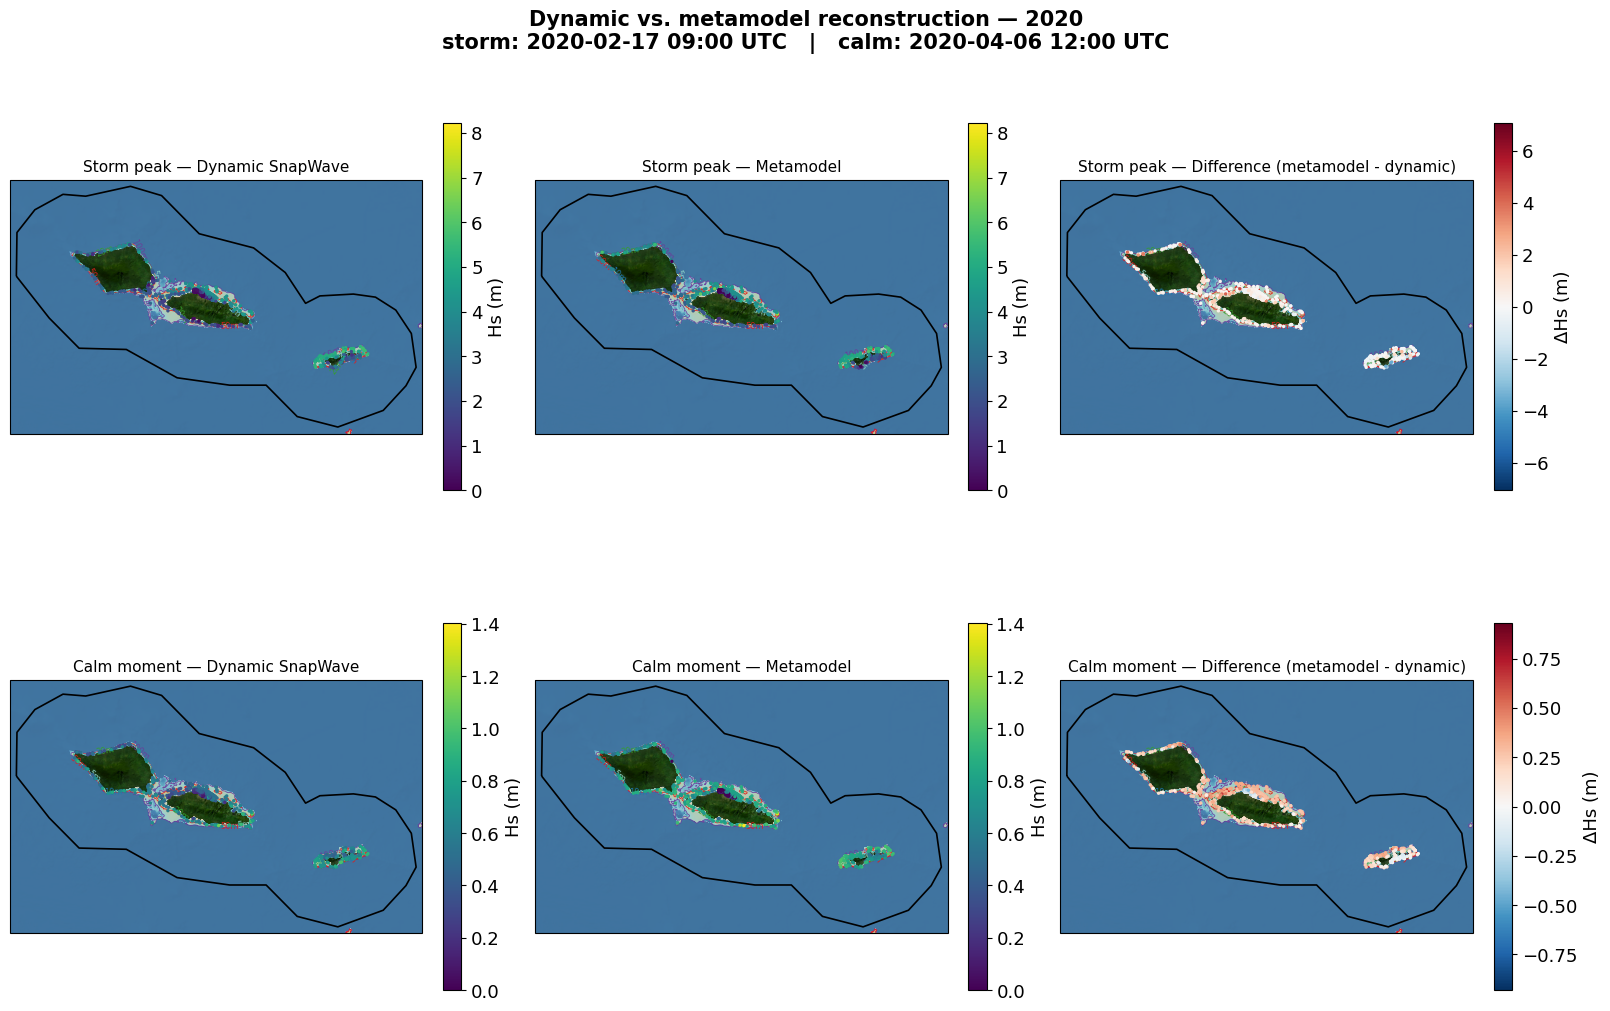

saved -> /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig02_map_comparison.png


PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig02_map_comparison.png')

In [ ]:
apply_slide_style()

storm_moment = pick_storm_peak_time(buoy_goal, period_=comparison_period)
calm_moment = pick_calm_time(buoy_goal, period_=comparison_period)
row_specs = [
    ("Storm peak", storm_moment, storm_moment.strftime("%Y-%m-%d")),
    ("Calm moment", calm_moment, calm_moment.strftime("%Y-%m-%d")),
]
for label, moment, day in row_specs:
    print(f"{label}: {moment}  (reconstructing day {day})")

# Same inner-join-on-shared-sites alignment 09_Validate_Linear_Summation.ipynb
# uses via val.compare() — reused directly rather than re-implementing it.
# Only the single day containing each moment is reconstructed (not the whole
# comparison_period) — same affordability reasoning as Fig 4's spectra
# network: per-goal model loading dominates the cost, not the number of
# reconstructed timesteps, so a 24-hour window keeps this a notebook-scale
# call instead of a batch job.
fig, axes = plt.subplots(
    2,
    3,
    figsize=(16.0, 10.5),
    constrained_layout=True,
    subplot_kw={"projection": ccrs.PlateCarree()},
)
lon = lat = None

for row, (row_label, moment, day) in enumerate(row_specs):
    metamodel_day = mm.reconstruct(
        day,
        mda_n,
        spectral=False,
        offshore_name=offshore_name,
        sites=None,
        pca_variance=pca_variance,
        workers=4,
        save_spectra=False,
    )
    dynamic_day = xr.open_dataset(dynamic_path).sel(time=day).load()
    dynamic_aligned, metamodel_aligned = val.align_pair(
        reference=dynamic_day, estimate=metamodel_day
    )
    if lon is None:
        lon = metamodel_aligned.site_longitude.values
        lat = metamodel_aligned.site_latitude.values
        print(
            f"Comparison sites: {metamodel_aligned.sizes['sites']} (isobath + buoy + mesh)"
        )

    dyn_hs = dynamic_aligned["hs"].sel(time=moment, method="nearest").values
    meta_hs = metamodel_aligned["hs"].sel(time=moment, method="nearest").values
    diff = meta_hs - dyn_hs
    vmax = float(np.nanmax([dyn_hs, meta_hs]))
    diff_abs = float(np.nanmax(np.abs(diff))) or 1.0

    panels = [
        (dyn_hs, "Dynamic SnapWave", "viridis", 0.0, vmax),
        (meta_hs, "Metamodel", "viridis", 0.0, vmax),
        (diff, "Difference (metamodel - dynamic)", "RdBu_r", -diff_abs, diff_abs),
    ]
    for col, (values, title, cmap, vmin, vc) in enumerate(panels):
        ax = axes[row, col]
        cp.plot_base_map(
            ax=ax,
            title=None,
            show_satellite=True,
            show_topobathy=True,
            show_isobaths=True,
            show_aoi=True,
        )
        sc = ax.scatter(
            lon,
            lat,
            c=values,
            cmap=cmap,
            vmin=vmin,
            vmax=vc,
            s=6,
            linewidths=0,
            zorder=4,
        )
        fig.colorbar(sc, ax=ax, shrink=0.75, label="Hs (m)" if col < 2 else "ΔHs (m)")
        ax.set_title(f"{row_label} — {title}", fontsize=11)
        ax.set_xlabel("")
        ax.set_ylabel("")

fig.suptitle(
    f"Dynamic vs. metamodel reconstruction — {comparison_period}\n"
    f"storm: {storm_moment:%Y-%m-%d %H:%M} UTC   |   calm: {calm_moment:%Y-%m-%d %H:%M} UTC",
    fontsize=15,
    fontweight="bold",
)

save_fig(fig, "fig02_map_comparison")

## Fig 3 — Metamodel training (LHS cases)

Sampled wave directions per goal from the **500 LHS SnapWave cases** (notebook 05).
Reuses the same diagnostic layout as case generation.


LHS cases loaded: 8,000 rows across 16 goals


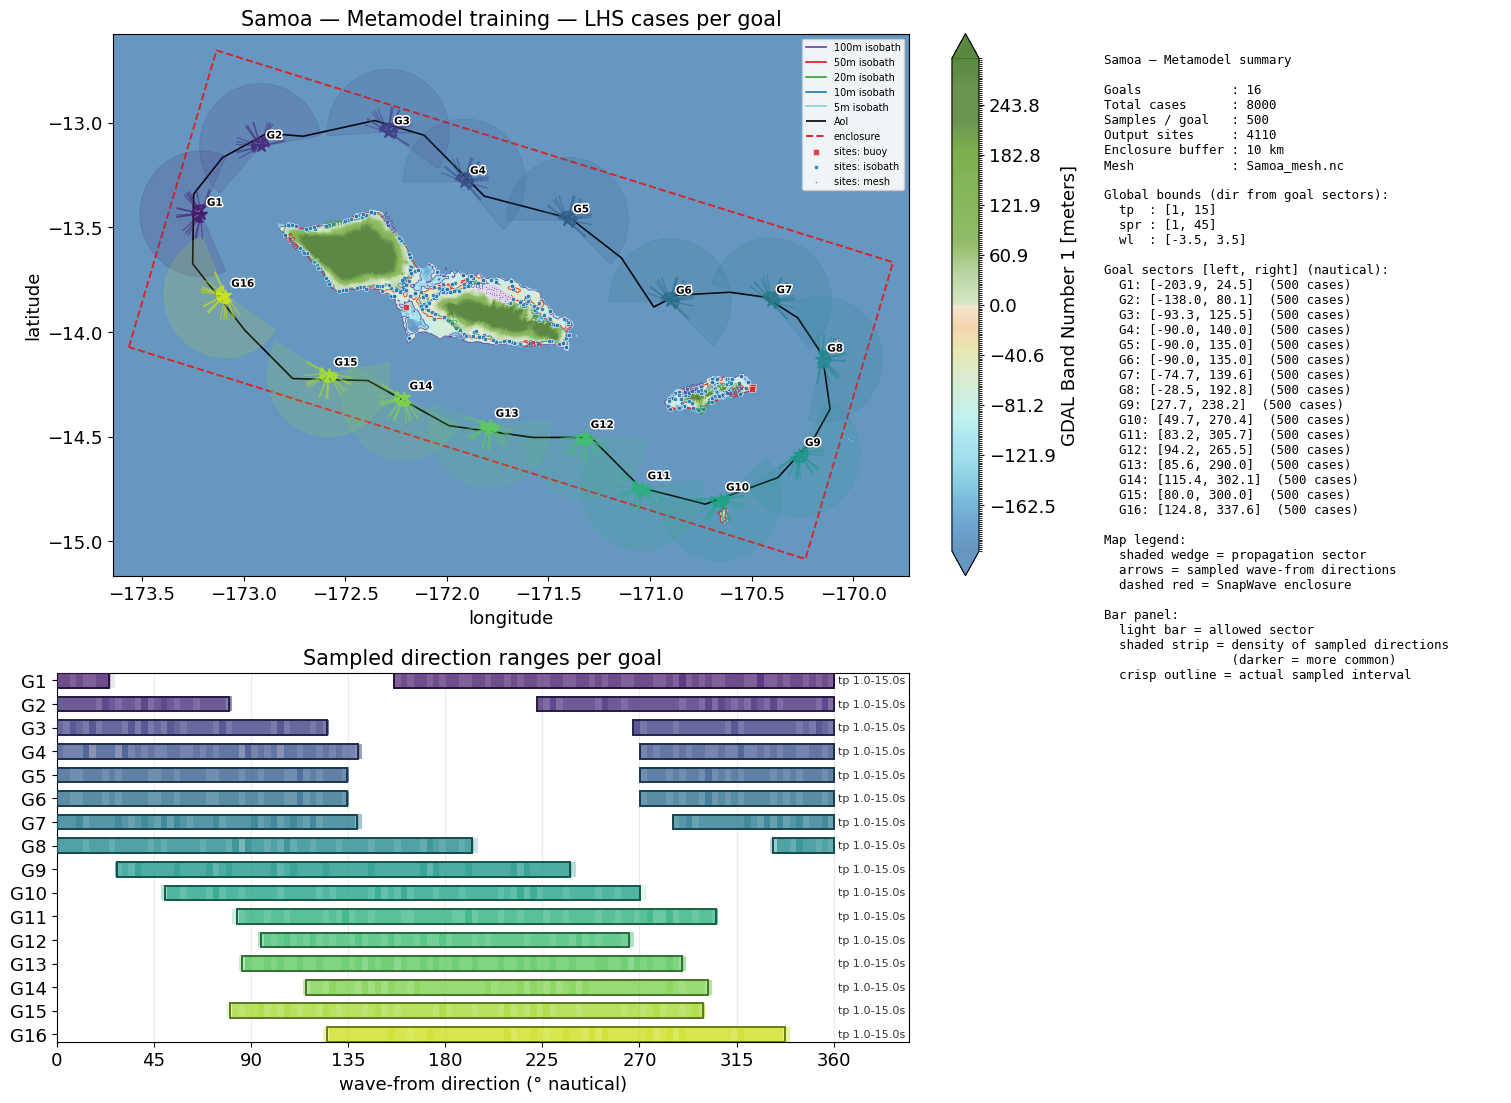

saved -> /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig03_metamodel.png


PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig03_metamodel.png')

In [ ]:
apply_slide_style()
lhs_cases = build_lhs_cases_df()
print(
    f"LHS cases loaded: {len(lhs_cases):,} rows across {lhs_cases['goal'].nunique()} goals"
)

fig = cp.plot_metamodel_configuration(
    aoi_gdf=aoi_gdf,
    enclosure_polygon=enclosure_polygon,
    goals_config=goals_config,
    cases_df=lhs_cases,
    output_sites_df=output_sites_df,
    bounds=SIMULATIONS.get("bounds"),
    num_samples_per_goal=SIMULATIONS.get("num_samples_per_goal"),
    mesh_file=PATHS.get("mesh_file"),
    enclosure_buffer_m=float(SIMULATIONS.get("enclosure_buffer_m", 10_000)),
    sector_radius_deg=0.30,
    arrow_scale_deg=0.12,
    max_arrows_per_goal=18,
    show_topobathy=True,
    title="Metamodel training — LHS cases per goal",
)
save_fig(fig, "fig03_metamodel")

## Fig 4 — Reconstruction spectra network

Reconstructed **spectra bubbles** stamped directly onto the map at
well-spaced sites along the 5 m isobath, together with the same WHACS
partition **forcing arrows** at the goals — one figure showing input
(arrows) and output (spectra spread across the whole domain) at the same
moment.

Only a single day (24 hours, containing `moment`) is reconstructed for these
sites — the cost here is dominated by per-goal model loading, not by the
number of days, so restricting the time window is what keeps this affordable.
The site list itself is spaced out precisely so the bubbles stay legible
instead of overlapping.

**Budget a few minutes the first time** this cell runs (one fresh
`mm.reconstruct(spectral=True, ...)` call); cached after that via
`tmp/reconstruct/`.


Spectra network moment: 2020-01-18 15:00:00  (reconstructing day 2020-01-18)


Spectra network sites: 25 (of 84 on 5 m isobath)


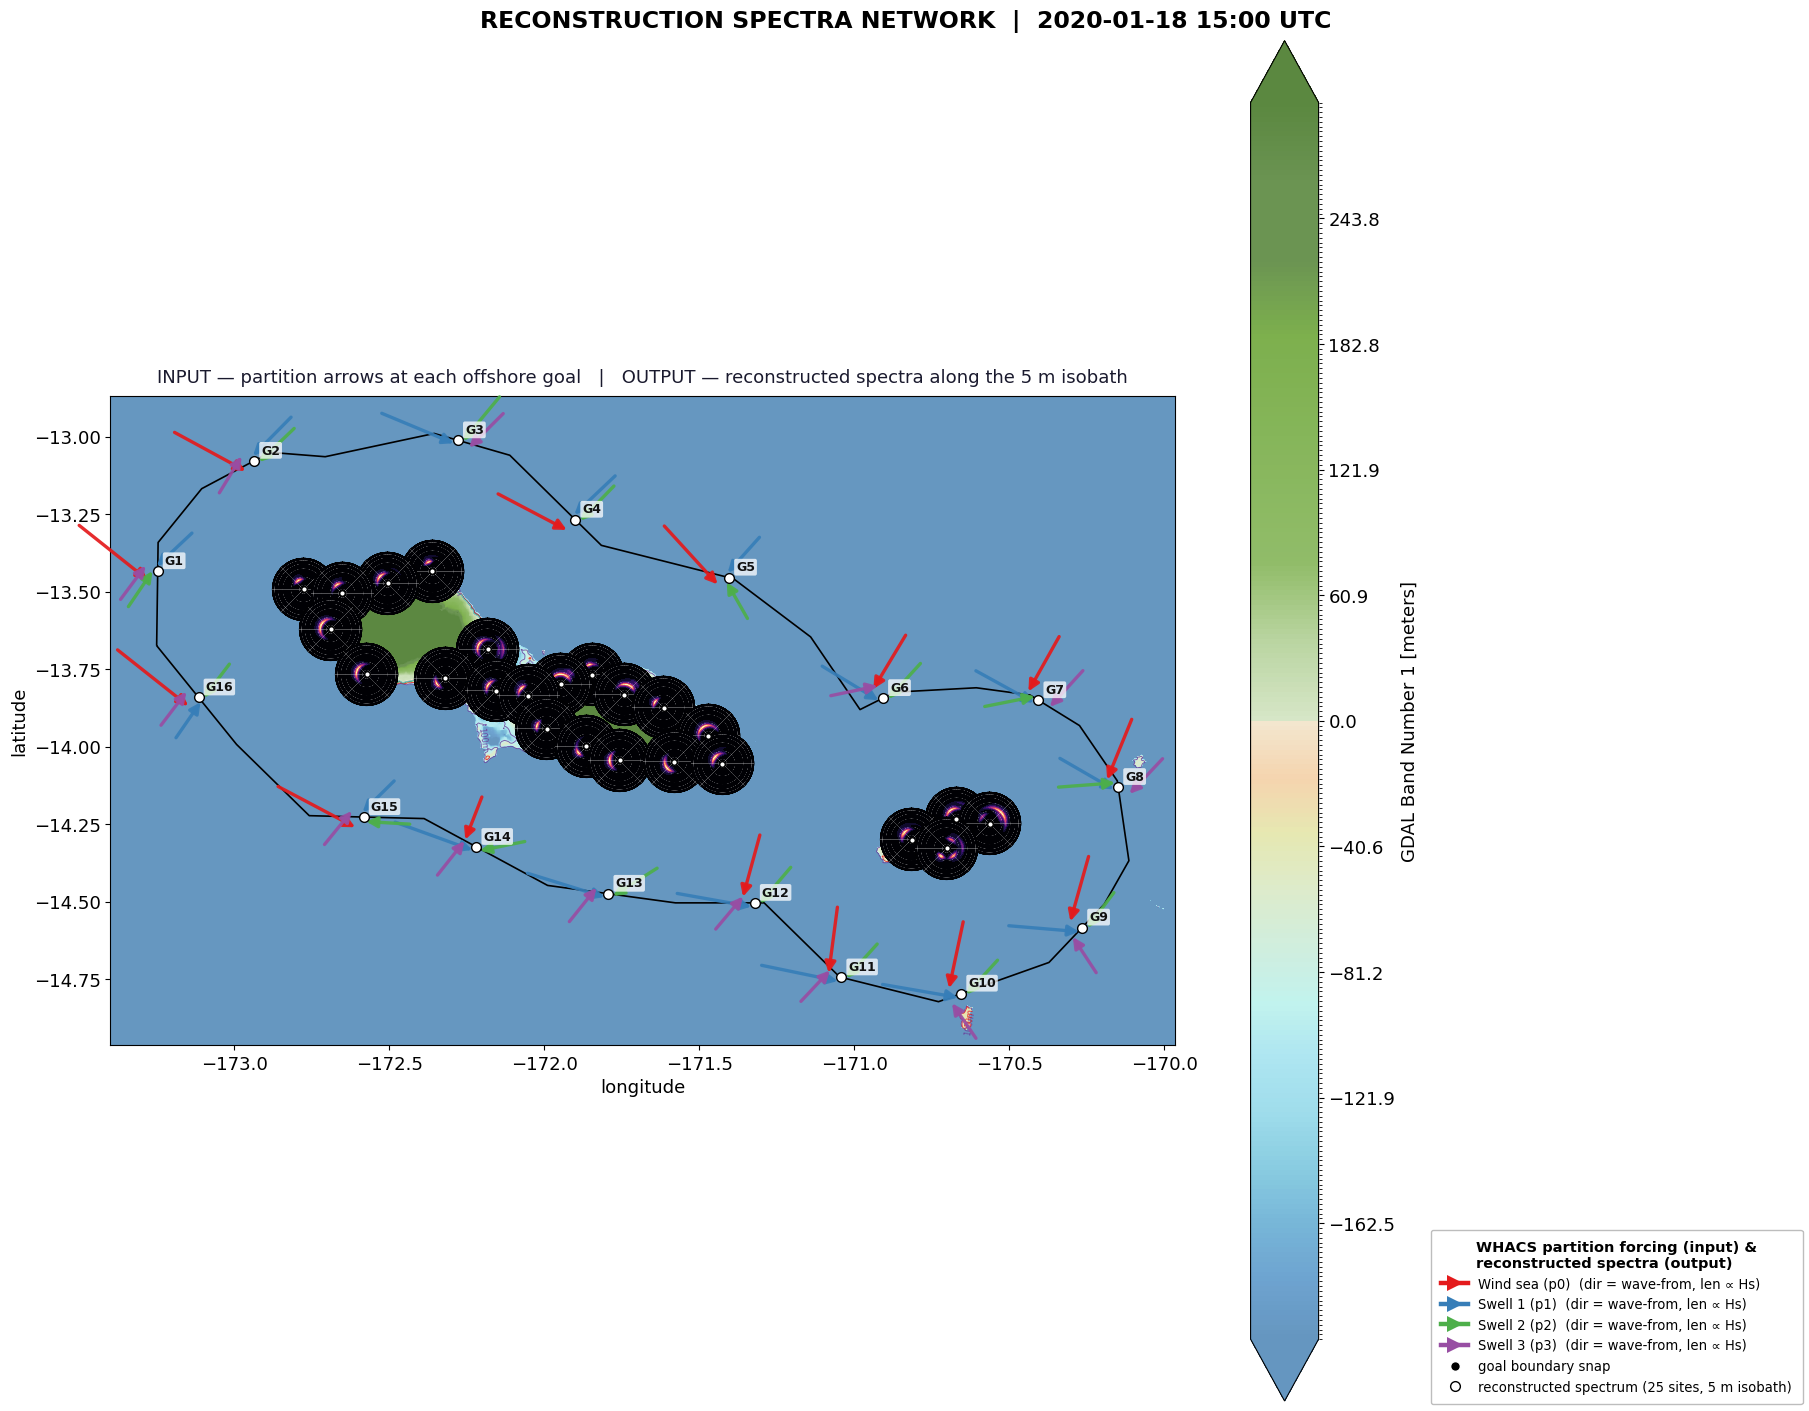

saved -> /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig04_spectra_reconstruction.png


PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig04_spectra_reconstruction.png')

In [ ]:
apply_slide_style()
moment = resolve_forcing_moment()
day = moment.strftime("%Y-%m-%d")
print(f"Spectra network moment: {moment}  (reconstructing day {day})")


def pick_spaced_sites(
    lons: np.ndarray, lats: np.ndarray, min_spacing_deg: float
) -> np.ndarray:
    """Greedy latitude-ordered subsample keeping a minimum on-map spacing.

    Checked against *every* previously kept point (not just the last one),
    so a simple running-neighbour check doesn't let clusters of
    near-duplicate points through.
    """
    order = np.argsort(lats)[::-1]
    picked: list[int] = []
    pts: list[np.ndarray] = []
    for idx in order:
        pt = np.array([lons[idx], lats[idx]])
        if not pts or all(np.hypot(*(pt - p)) >= min_spacing_deg for p in pts):
            picked.append(idx)
            pts.append(pt)
    return np.array(picked)


active_goals = list(goals.keys())
template = mm.load_cases_goal(active_goals[0])
common_5m = [s for s in mm.common_model_sites(active_goals) if s.startswith("5m_")]
lon_5m = template.site_longitude.sel(sites=common_5m).values
lat_5m = template.site_latitude.sel(sites=common_5m).values

keep = pick_spaced_sites(lon_5m, lat_5m, min_spacing_deg=0.1)
network_site_ids = [common_5m[i] for i in keep]
print(
    f"Spectra network sites: {len(network_site_ids)} (of {len(common_5m)} on 5 m isobath)"
)

network_kw = dict(
    n=mda_n,
    offshore_name=offshore_name,
    goals=None,
    wl=wl,
    pca_variance=pca_variance,
)

mm.reconstruct(
    day, spectral=True, sites=network_site_ids, save_spectra=True, **network_kw
)
network_spec = mm.load_reconstruction_spectra(
    day, spectral=True, site_ids=network_site_ids, **network_kw
)
if network_spec is None:
    raise FileNotFoundError(
        f"Missing spectra cache for {day!r} - check mm.reconstruct(save_spectra=True) above."
    )
network_efth = network_spec["efth"].sel(time=moment, method="nearest")

fig, ax = plt.subplots(figsize=(18.0, 14.0), constrained_layout=True)
cp.plot_base_map(ax=ax, title=None, show_topobathy=True)
draw_goal_partition_arrows(ax, moment)

for site_id in network_site_ids:
    da = network_efth.sel(sites=site_id)
    if not np.isfinite(da.values).any() or float(da.max()) <= 0:
        continue
    lon = float(network_spec.site_longitude.sel(sites=site_id))
    lat = float(network_spec.site_latitude.sel(sites=site_id))
    img = render_spectrum_bubble(da, figsize=(1.9, 1.9))
    ax.plot(
        lon, lat, "o", color="white", markeredgecolor="black", markersize=4, zorder=7
    )
    ax.add_artist(
        AnnotationBbox(
            OffsetImage(np.asarray(img), zoom=0.24),
            (lon, lat),
            frameon=False,
            pad=0,
            zorder=6,
        )
    )

x0, x1, y0, y1 = course_map_extent()
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_aspect("equal", adjustable="box")
ax.set_title(
    "INPUT — partition arrows at each offshore goal   |   "
    "OUTPUT — reconstructed spectra along the 5 m isobath",
    fontsize=13,
    pad=10,
    color="#1a1a2e",
)

legend_handles = partition_legend_handles() + [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=7,
        linestyle="None",
        label=f"reconstructed spectrum ({len(network_site_ids)} sites, 5 m isobath)",
    )
]
leg = fig.legend(
    handles=legend_handles,
    loc="outside right lower",
    fontsize=9.5,
    framealpha=0.96,
    edgecolor="#bbbbbb",
    title="WHACS partition forcing (input) &\nreconstructed spectra (output)",
    title_fontsize=10.5,
    ncol=1,
    borderpad=0.8,
)
leg.get_title().set_fontweight("bold")

fig.suptitle(
    f"RECONSTRUCTION SPECTRA NETWORK  |  {moment:%Y-%m-%d %H:%M} UTC",
    fontsize=17,
    fontweight="bold",
)

save_fig(fig, "fig04_spectra_reconstruction")

## Export summary


In [ ]:
sorted(EXPORT_DIR.glob("fig*.png"))

[PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig01_domain.png'),
 PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig02_map_comparison.png'),
 PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig03_metamodel.png'),
 PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig03_metamodel_lhs.png'),
 PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig04_spectra_reconstruction.png'),
 PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig11_reconstruction_spectra_network.png'),
 PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/outputs/gui_figures/fig_reconstruction_comparison.png')]